In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA

print("Week 7 - Feature Selection and PCA")
print("Libraries imported successfully!")

Week 7 - Feature Selection and PCA
Libraries imported successfully!


In [10]:
import pandas as pd

df = pd.read_csv('/content/Week6_Feature_Engineered_Dataset.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (2700, 12)


,year,player_id,player_name,team,base_price_lakh,final_price_lakh,role,nationality,status,acquisition_type,source,final_price_log
0,2008,P0473,MS Dhoni,CSK,NaN,950.0,Wicket-Keeper,Indian,SOLD,auction,manual_2008,6.857514
1,2008,P0011,Andrew Symonds,DCH,NaN,650.0,All-Rounder,Overseas,SOLD,auction,manual_2008,6.478510
2,2008,P0709,Sanath Jayasuriya,MI,NaN,575.0,All-Rounder,Overseas,SOLD,auction,manual_2008,6.356108
3,2008,P0295,Ishant Sharma,KKR,NaN,550.0,Bowler,Indian,SOLD,auction,manual_2008,6.311735
4,2008,P0207,Mahela Jayawardene,DC,NaN,525.0,Batsman,Overseas,SOLD,auction,manual_2008,6.265301


In [11]:
print("Dataset Information")
print("-" * 40)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information
----------------------------------------
Rows: 2700
Columns: 12

Column Names:
['year', 'player_id', 'player_name', 'team', 'base_price_lakh', 'final_price_lakh', 'role', 'nationality', 'status', 'acquisition_type', 'source', 'final_price_log']

Data Types:
year                  int64
player_id            object
player_name          object
team                 object
base_price_lakh     float64
final_price_lakh    float64
role                 object
nationality          object
status               object
acquisition_type     object
source               object
final_price_log     float64
dtype: object

Missing Values:
year                   0
player_id             72
player_name            0
team                   0
base_price_lakh     2348
final_price_lakh     303
role                1275
nationality         1123
status                 0
acquisition_type       0
source                 0
final_price_log      303
dtype: int64


In [12]:
numerical_df = df.select_dtypes(include=np.number)

print("Numerical Features:")
print(numerical_df.columns.tolist())

print("\nNumerical Dataset Shape:", numerical_df.shape)

display(numerical_df.head())

Numerical Features:
['year', 'base_price_lakh', 'final_price_lakh', 'final_price_log']

Numerical Dataset Shape: (2700, 4)


,year,base_price_lakh,final_price_lakh,final_price_log
0,2008,NaN,950.0,6.857514
1,2008,NaN,650.0,6.478510
2,2008,NaN,575.0,6.356108
3,2008,NaN,550.0,6.311735
4,2008,NaN,525.0,6.265301


In [13]:
numerical_df = numerical_df.replace([np.inf, -np.inf], np.nan)

missing_before = numerical_df.isnull().sum()

print("Missing Values Before Imputation:")
print(missing_before)

numerical_df = numerical_df.fillna(numerical_df.median())

print("\nMissing Values After Imputation:")
print(numerical_df.isnull().sum())

Missing Values Before Imputation:
year                   0
base_price_lakh     2348
final_price_lakh     303
final_price_log      303
dtype: int64

Missing Values After Imputation:
year                0
base_price_lakh     0
final_price_lakh    0
final_price_log     0
dtype: int64


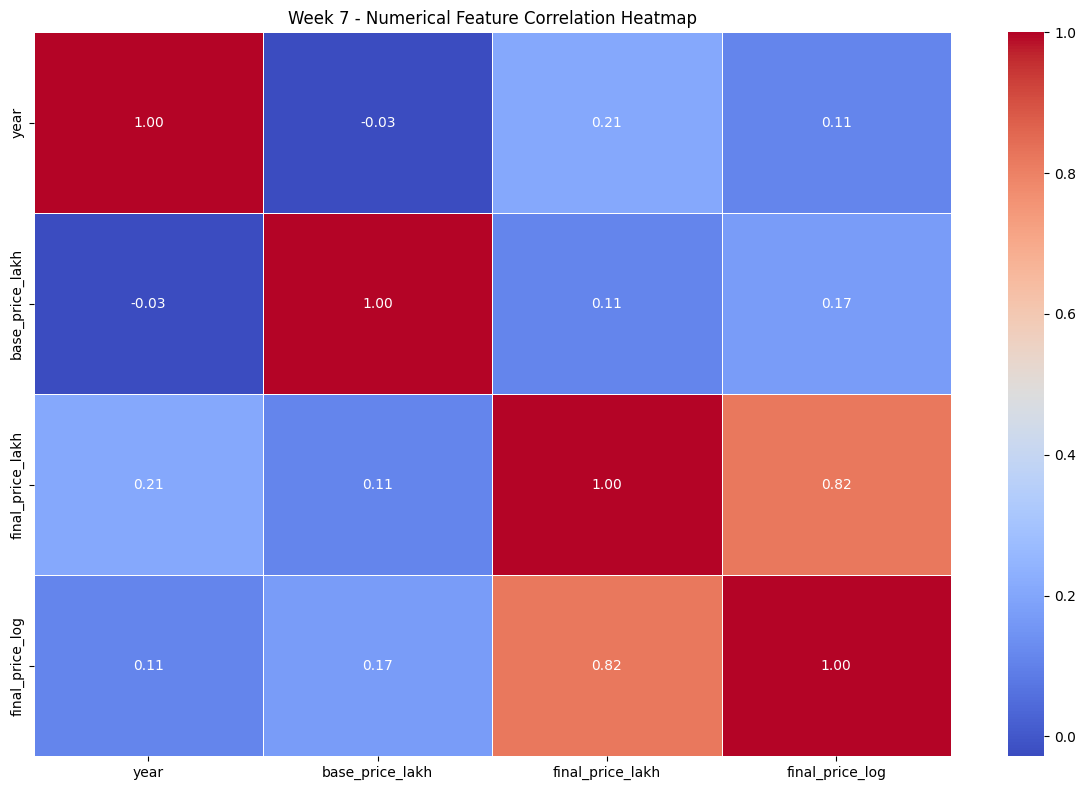

In [14]:
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Week 7 - Numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

Feature Variance:
final_price_log          1.765258
year                    24.171293
base_price_lakh        409.864569
final_price_lakh    136837.231421
dtype: float64


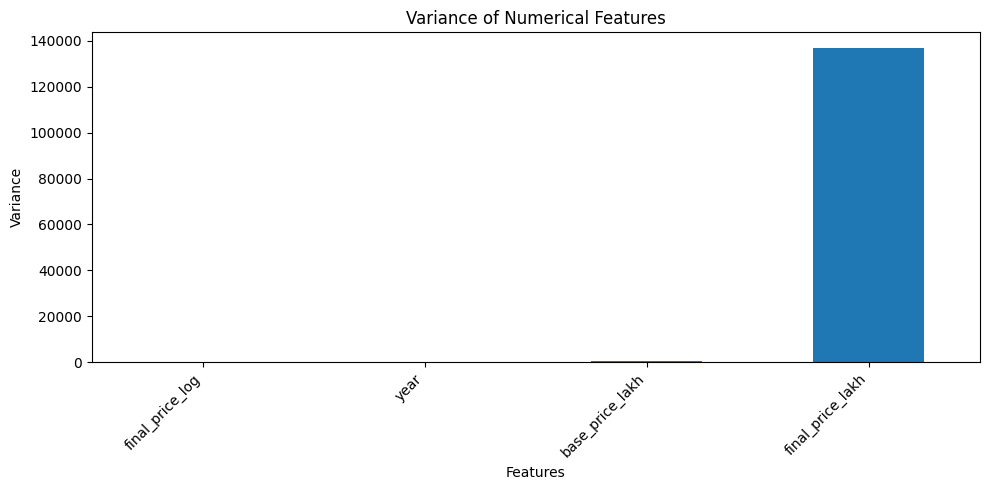

In [15]:
variance_values = numerical_df.var()

print("Feature Variance:")
print(variance_values.sort_values())

plt.figure(figsize=(10, 5))

variance_values.sort_values().plot(kind="bar")

plt.title("Variance of Numerical Features")
plt.xlabel("Features")
plt.ylabel("Variance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [16]:
selector = VarianceThreshold(threshold=0)

selected_array = selector.fit_transform(numerical_df)

selected_columns = numerical_df.columns[selector.get_support()]

selected_df = pd.DataFrame(
    selected_array,
    columns=selected_columns,
    index=numerical_df.index
)

print("Original Numerical Features:", numerical_df.shape[1])
print("Selected Features:", selected_df.shape[1])

print("\nSelected Feature Names:")
print(selected_columns.tolist())

display(selected_df.head())

Original Numerical Features: 4
Selected Features: 4

Selected Feature Names:
['year', 'base_price_lakh', 'final_price_lakh', 'final_price_log']


,year,base_price_lakh,final_price_lakh,final_price_log
0,2008.0,45.0,950.0,6.857514
1,2008.0,45.0,650.0,6.478510
2,2008.0,45.0,575.0,6.356108
3,2008.0,45.0,550.0,6.311735
4,2008.0,45.0,525.0,6.265301


In [17]:
scaler = StandardScaler()

scaled_array = scaler.fit_transform(selected_df)

scaled_df = pd.DataFrame(
    scaled_array,
    columns=selected_df.columns,
    index=selected_df.index
)

print("Standardization Completed!")

print("\nFeature Means:")
print(scaled_df.mean().round(4))

print("\nFeature Standard Deviations:")
print(scaled_df.std(ddof=0).round(4))

display(scaled_df.head())

Standardization Completed!

Feature Means:
year               -0.0
base_price_lakh     0.0
final_price_lakh    0.0
final_price_log    -0.0
dtype: float64

Feature Standard Deviations:
year                1.0
base_price_lakh     1.0
final_price_lakh    1.0
final_price_log     1.0
dtype: float64


,year,base_price_lakh,final_price_lakh,final_price_log
0,-1.820085,-0.122155,1.781648,1.465770
1,-1.820085,-0.122155,0.970501,1.180457
2,-1.820085,-0.122155,0.767714,1.088314
3,-1.820085,-0.122155,0.700118,1.054910
4,-1.820085,-0.122155,0.632523,1.019955


In [18]:
pca = PCA()

pca_result = pca.fit_transform(scaled_df)

pca_columns = [
    f"PC{i+1}" for i in range(pca_result.shape[1])
]

pca_df = pd.DataFrame(
    pca_result,
    columns=pca_columns,
    index=scaled_df.index
)

print("PCA Completed!")
print("Original Feature Count:", scaled_df.shape[1])
print("Principal Component Count:", pca_df.shape[1])

display(pca_df.head())

PCA Completed!
Original Feature Count: 4
Principal Component Count: 4


,PC1,PC2,PC3,PC4
0,1.752371,1.157914,-2.024248,0.375806
1,1.011610,1.181981,-1.800708,0.001526
2,0.812443,1.186492,-1.740005,-0.077468
3,0.744248,1.187802,-1.719148,-0.101916
4,0.675012,1.188999,-1.697932,-0.125278


In [19]:
explained_variance = pca.explained_variance_ratio_

variance_df = pd.DataFrame({
    "Principal Component": pca_columns,
    "Explained Variance Ratio": explained_variance,
    "Explained Variance Percentage": explained_variance * 100,
    "Cumulative Variance Percentage": np.cumsum(explained_variance) * 100
})

display(variance_df.round(4))

,Principal Component,Explained Variance Ratio,Explained Variance Percentage,Cumulative Variance Percentage
0,PC1,0.4787,47.8728,47.8728
1,PC2,0.2587,25.8724,73.7452
2,PC3,0.2196,21.9646,95.7097
3,PC4,0.0429,4.2903,100.0000


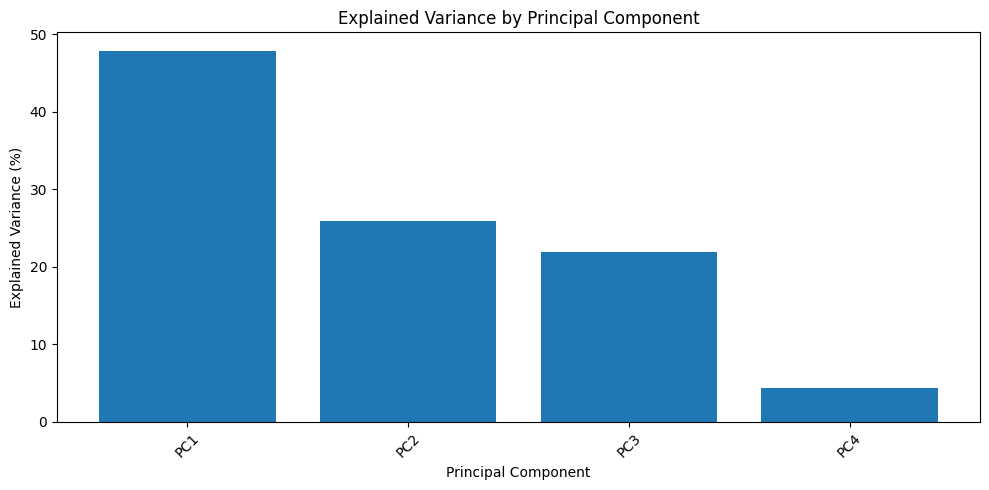

In [20]:
plt.figure(figsize=(10, 5))

plt.bar(pca_columns, explained_variance * 100)

plt.title("Explained Variance by Principal Component")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

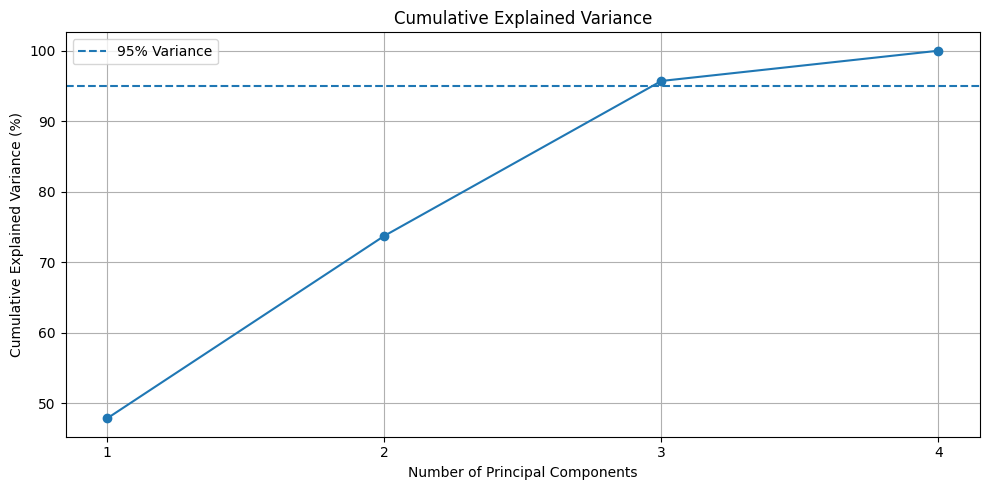

In [21]:
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

plt.axhline(
    y=95,
    linestyle="--",
    label="95% Variance"
)

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")

plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components Required for 95% Variance:", n_components_95)
print(
    "Cumulative Variance Explained:",
    round(cumulative_variance[n_components_95 - 1] * 100, 2),
    "%"
)

Components Required for 95% Variance: 3
Cumulative Variance Explained: 95.71 %


In [23]:
pca_95 = PCA(n_components=n_components_95)

reduced_array = pca_95.fit_transform(scaled_df)

reduced_columns = [
    f"PC{i+1}" for i in range(n_components_95)
]

reduced_df = pd.DataFrame(
    reduced_array,
    columns=reduced_columns,
    index=scaled_df.index
)

print("PCA Dimensionality Reduction Completed!")
print("Before PCA:", scaled_df.shape)
print("After PCA:", reduced_df.shape)

display(reduced_df.head())

PCA Dimensionality Reduction Completed!
Before PCA: (2700, 4)
After PCA: (2700, 3)


,PC1,PC2,PC3
0,1.752371,1.157914,-2.024248
1,1.011610,1.181981,-1.800708
2,0.812443,1.186492,-1.740005
3,0.744248,1.187802,-1.719148
4,0.675012,1.188999,-1.697932


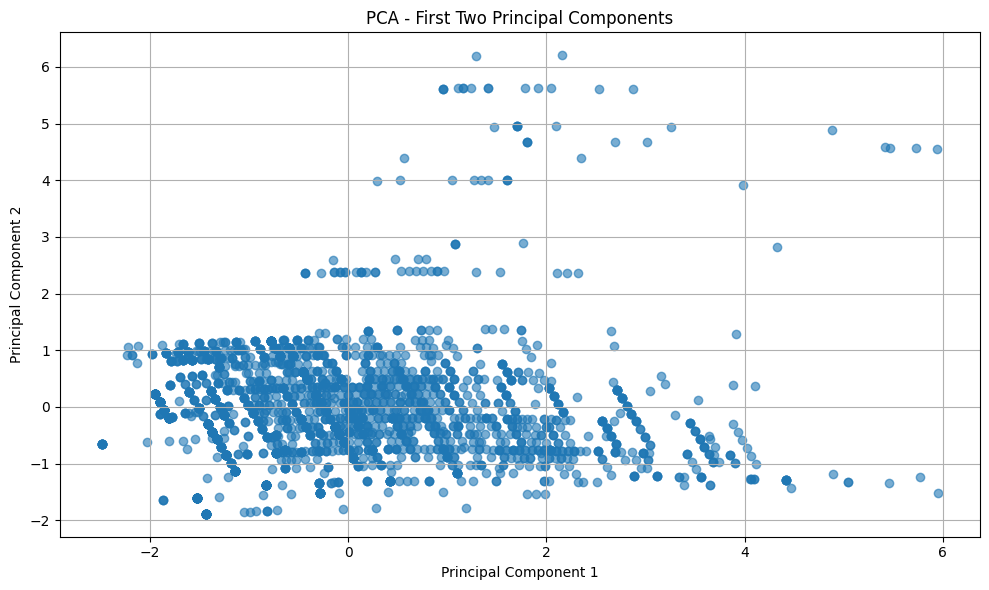

In [24]:
if reduced_df.shape[1] >= 2:
    plt.figure(figsize=(10, 6))

    plt.scatter(
        reduced_df["PC1"],
        reduced_df["PC2"],
        alpha=0.6
    )

    plt.title("PCA - First Two Principal Components")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Only one component selected. PC1 vs PC2 plot is unavailable.")

In [25]:
loadings_df = pd.DataFrame(
    pca.components_.T,
    index=scaled_df.columns,
    columns=pca_columns
)

print("PCA Component Loadings:")

display(loadings_df.round(4))

PCA Component Loadings:


,PC1,PC2,PC3,PC4
year,0.2274,-0.6807,0.6917,-0.0808
base_price_lakh,0.1975,0.7269,0.6560,0.0476
final_price_lakh,0.6770,-0.0551,-0.1942,0.7077
final_price_log,0.6715,0.0723,-0.2315,-0.7002


In [26]:
variance_df.to_csv(
    "Week7_Explained_Variance.csv",
    index=False
)

loadings_df.to_csv(
    "Week7_PCA_Loadings.csv"
)

reduced_df.to_csv(
    "Week7_PCA_Reduced_Dataset.csv",
    index=False
)

selected_df.to_csv(
    "Week7_Selected_Numerical_Features.csv",
    index=False
)

print("Week 7 result files saved successfully!")

Week 7 result files saved successfully!


In [27]:
print("=" * 50)
print("WEEK 7 - FEATURE SELECTION AND PCA SUMMARY")
print("=" * 50)

print("Original Dataset Shape:", df.shape)
print("Numerical Feature Count:", numerical_df.shape[1])
print("Features After Constant-Feature Removal:", selected_df.shape[1])
print("Components Required for 95% Variance:", n_components_95)
print("PCA Dataset Shape:", reduced_df.shape)

print("\nWeek 7 analysis completed successfully!")

WEEK 7 - FEATURE SELECTION AND PCA SUMMARY
Original Dataset Shape: (2700, 12)
Numerical Feature Count: 4
Features After Constant-Feature Removal: 4
Components Required for 95% Variance: 3
PCA Dataset Shape: (2700, 3)

Week 7 analysis completed successfully!
